In [1]:
import copy
import random
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

SEED = 42  # standard magic number for reproducibility
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # fingers crossed for a GPU
OUT_DIR = Path("task1_outputs")
OUT_DIR.mkdir(exist_ok=True)  # make sure the folder exists so we don't crash at the very end
QUICK = False  # flip this to True for a quick dry-run (3 epochs) to hunt down bugs
EPOCHS_FM = 3 if QUICK else 15      
EPOCHS_CIFAR = 3 if QUICK else 25    
BATCH_SIZE = 128  # standard mini-batch size, seems to fit nicely in memory

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) 
    # Force deterministic algorithms (can be a bit slower but worth it for reproducible results)
    torch.backends.cudnn.deterministic = True 
    torch.backends.cudnn.benchmark = False 

set_seed()
print(f"Running on {DEVICE} | Epochs (FM/CIFAR): {EPOCHS_FM}/{EPOCHS_CIFAR} | Batch: {BATCH_SIZE}")

Running on cuda | Epochs (FM/CIFAR): 15/25 | Batch: 128


In [2]:
class TensorLoader:
    def __init__(self, x, y, batch_size, shuffle): 
        self.x = x
        self.y = y
        self.bs = batch_size
        self.shuffle = shuffle        
    def __len__(self): 
        # Ceiling division to get the total number of batches
        return (len(self.x) + self.bs - 1) // self.bs 
    def __iter__(self): 
        n = len(self.x)
        # Randomize indices for training, keep them fixed for val/test
        idx = torch.randperm(n, device=self.x.device) if self.shuffle else torch.arange(n, device=self.x.device) 
        # Step through the dataset in batch-sized chunks
        for i in range(0, n, self.bs):
            b = idx[i:i + self.bs] 
            yield self.x[b], self.y[b]

def to_tensors(ds):
    x = torch.as_tensor(np.asarray(ds.data)).float() / 255.0  # normalize pixel values to [0, 1]
    # Fix channel dimensions: Fashion-MNIST needs a channel dim, CIFAR needs channels first (N, C, H, W)
    x = x.unsqueeze(1) if x.ndim == 3 else x.permute(0, 3, 1, 2)  
    y = torch.as_tensor(ds.targets).long()  
    return x, y                                                      

def load_data(name, root="./data", val_frac=0.1, batch_size=BATCH_SIZE): 
    cls = {"fashion": datasets.FashionMNIST, "cifar10": datasets.CIFAR10}[name] 
    # Grab the official splits (this will download them if running for the first time)
    x_all, y_all = to_tensors(cls(root, train=True, download=True)) 
    x_te, y_te = to_tensors(cls(root, train=False, download=True)) 
    # Create a dedicated seeded generator just for the split so it stays consistent
    g = torch.Generator().manual_seed(SEED)                          
    perm = torch.randperm(len(x_all), generator=g)                     
    # Carve out a validation set (e.g., 10%)
    n_val = int(val_frac * len(x_all))                               
    val_idx, tr_idx = perm[:n_val], perm[n_val:]                     
    x_tr, y_tr, x_val, y_val = x_all[tr_idx], y_all[tr_idx], x_all[val_idx], y_all[val_idx]  
    # Crucial step: calculate mean/std ONLY on the training data to avoid leaking info from val/test
    mean = x_tr.mean(dim=(0, 2, 3), keepdim=True) 
    std = x_tr.std(dim=(0, 2, 3), keepdim=True) 
    norm = lambda t: ((t - mean) / std).to(DEVICE) 
    # Apply normalization and push everything to the target device (GPU/CPU)
    x_tr, x_val, x_te = norm(x_tr), norm(x_val), norm(x_te) 
    y_tr, y_val, y_te = y_tr.to(DEVICE), y_val.to(DEVICE), y_te.to(DEVICE) 
    return {"name": name, "in_shape": tuple(x_tr.shape[1:]), "train": TensorLoader(x_tr, y_tr, batch_size, shuffle=True), "val": TensorLoader(x_val, y_val, batch_size, shuffle=False), "test": TensorLoader(x_te, y_te, batch_size, shuffle=False), "sizes": (len(x_tr), len(x_val), len(x_te))}

# Sanity check to make sure things loaded correctly
data_fm = load_data("fashion")
print(f"Fashion-MNIST loaded Shape: {data_fm['in_shape']} | Train/Val/Test splits: {data_fm['sizes']}")

Fashion-MNIST loaded Shape: (1, 28, 28) | Train/Val/Test splits: (54000, 6000, 10000)


In [3]:
ACTS = {"relu": lambda: nn.ReLU(), "leaky_relu": lambda: nn.LeakyReLU(0.1), "gelu": lambda: nn.GELU()}                                      

class MLP(nn.Module):
    def __init__(self, in_shape, n_classes=10, hidden=256, depth=2, act="relu", dropout=0.0):
        super().__init__()
        # Start by flattening the 2D image into a 1D vector. 
        # d keeps track of the current feature size as we build the layers.
        layers, d = [nn.Flatten()], int(np.prod(in_shape))
        # Build the hidden layers dynamically based on the requested depth
        for _ in range(depth):
            # The standard block: Linear -> Activation -> Dropout
            layers += [nn.Linear(d, hidden), ACTS[act](), nn.Dropout(dropout)]
            d = hidden  # The input size for the next layer is this layer's output size
        # Final classification head (raw logits, no softmax needed since CrossEntropyLoss handles it)
        layers.append(nn.Linear(d, n_classes)) 
        self.net = nn.Sequential(*layers) 
    def forward(self, x):
        return self.net(x) 
    
class CNN(nn.Module): 
    def __init__(self, in_shape, n_classes=10, channels=(32, 64), kernel=3, fc=128, act="relu", dropout=0.0): 
        super().__init__() 
        c, h, w = in_shape  # Unpack input shape (channels, height, width)                                            
        layers = [] 
        # Build the convolutional feature extractor
        for ch in channels:  
            # 'padding=kernel//2' ensures 'same' padding so spatial dimensions don't shrink from the conv itself
            layers += [nn.Conv2d(c, ch, kernel, padding=kernel // 2), ACTS[act](), nn.MaxPool2d(2)] # Halves the height and width 
            # Update running trackers for channels and spatial dimensions
            c, h, w = ch, h // 2, w // 2   
        # Flatten the spatial maps and push through a dense block before classification
        layers += [nn.Flatten(), nn.Linear(c * h * w, fc), ACTS[act](), nn.Dropout(dropout), nn.Linear(fc, n_classes)]                                             
        self.net = nn.Sequential(*layers)

    def forward(self, x):                                             
        return self.net(x)                                          

def init_weights(model, scheme):
    if scheme == "default": 
        return  # Do nothing, let PyTorch use its default (Kaiming uniform)
    for m in model.modules():                                         
        if isinstance(m, (nn.Linear, nn.Conv2d)): # We only want to touch layers with trainable weights                      
            if scheme == "xavier":                                   
                nn.init.xavier_uniform_(m.weight) # Great for symmetric activations like Tanh                     
            elif scheme == "kaiming":                                  
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu") # The go-to for ReLU networks
            elif scheme == "normal":                                   
                nn.init.normal_(m.weight, mean=0.0, std=0.02)  # Old-school small gaussian        
            elif scheme == "zeros": 
                # Deliberately terrible initialization to prove a point. 
                # Symmetry won't break, and the network will fail to learn.
                nn.init.zeros_(m.weight)                               
            else: 
                raise ValueError(f"Unknown init scheme: {scheme}") 
            # Always start biases at 0
            nn.init.zeros_(m.bias) 

def make_model(cfg, in_shape): 
    if cfg["model"] == "mlp":                                        
        m = MLP(in_shape, hidden=cfg["hidden"], depth=cfg["depth"], act=cfg["act"], dropout=cfg["dropout"]) 
    else:                                                              
        m = CNN(in_shape, channels=cfg["channels"], kernel=cfg["kernel"], fc=cfg["fc"], act=cfg["act"], dropout=cfg["dropout"])                
    init_weights(m, cfg["init"]) 
    return m.to(DEVICE) # Ship it to the GPU if we have one                                               

def make_optimizer(params, name, lr, wd):                             
    if name == "sgd":                                                 
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    if name == "adam":                                                 
        return torch.optim.Adam(params, lr=lr, weight_decay=wd) # Standard Adam (L2 penalty via wd)      
    if name == "adamw":                                               
        return torch.optim.AdamW(params, lr=lr, weight_decay=wd) # AdamW (decoupled weight decay, usually better)
    raise ValueError(name)

In [4]:
@torch.no_grad() # Crucial: tells PyTorch not to track gradients here, saving tons of memory
def evaluate(model, loader): 
    model.eval() # Puts model in eval mode (disables dropout, freezes batchnorm)
    loss_sum, correct, n = 0.0, 0, 0 
    for x, y in loader:                                                
        out = model(x)                                                 
        loss_sum += F.cross_entropy(out, y, reduction="sum").item()    
        correct += (out.argmax(1) == y).sum().item()                   
        n += len(y)                                                    
    return loss_sum / n, correct / n                                   

def fit(model, train_loader, val_loader, optimizer, epochs):           
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}   
    best_acc, best_state, best_epoch = -1.0, None, -1                  
    for ep in range(epochs):                                           
        model.train() # Make sure training mode is back on                                                 
        loss_sum, correct, n = 0.0, 0, 0                                  
        for x, y in train_loader:                                      
            optimizer.zero_grad() # Wipe the slate clean for the new batch gradients                                     
            out = model(x)                                             
            loss = F.cross_entropy(out, y)                             
            loss.backward() # Magic happens here (backprop)                                           
            optimizer.step() # Nudge the weights                                          
            # Accumulate metrics
            loss_sum += loss.item() * len(y)                           
            correct += (out.argmax(1) == y).sum().item()               
            n += len(y)                                                 
        # Check how we are doing on the validation set
        val_loss, val_acc = evaluate(model, val_loader)                
        # Log history for plotting later
        hist["train_loss"].append(loss_sum / n)                        
        hist["train_acc"].append(correct / n)                          
        hist["val_loss"].append(val_loss)                              
        hist["val_acc"].append(val_acc)                                
        # If this is the best we've seen, save a snapshot of the weights
        if val_acc > best_acc:                                         
            best_acc, best_epoch = val_acc, ep                         
            best_state = copy.deepcopy(model.state_dict())             
    # Training is done. Reload the best weights so we don't return an overfitted final epoch model
    model.load_state_dict(best_state)                                  
    return hist, best_acc, best_epoch                                  

def run_experiment(cfg, data, epochs, keep_model=False):               
    set_seed(SEED)  # Reset seed before EVERY run to ensure completely fair comparisons                                                   
    model = make_model(cfg, data["in_shape"])                          
    opt = make_optimizer(model.parameters(), cfg["opt"], cfg["lr"], cfg["wd"])   
    t0 = time.time()                                                   
    hist, best_val, best_ep = fit(model, data["train"], data["val"], opt, epochs)   
    res = {                                                            
        "model": cfg["model"],                                         
        "val_acc": best_val,                                           
        "best_epoch": best_ep + 1, # 1-based indexing for humans                                    
        "train_acc_at_best": hist["train_acc"][best_ep],               
        "gap": hist["train_acc"][best_ep] - best_val, # Big positive gap = overfitting                 
        "n_params": sum(p.numel() for p in model.parameters()),        
        "time_s": time.time() - t0,                                    
        "cfg": cfg,                                                    
        "hist": hist,                                                  
    }
    # We don't want to keep every model in RAM (out of memory risk), 
    # so we only attach it if explicitly asked (usually for the final evaluation)
    if keep_model:                                                     
        res["torch_model"] = model                                     
    return res

In [5]:
# Our control groups: a basic MLP and a basic CNN
BASE = {"mlp": dict(model="mlp", hidden=256, depth=2, act="relu", init="default", opt="adam", lr=1e-3, wd=0.0, dropout=0.0),
    "cnn": dict(model="cnn", channels=(32, 64), kernel=3, fc=128, act="relu", init="default", opt="adam", lr=1e-3, wd=0.0, dropout=0.0)}

# Hyperparameters that apply to both model types
COMMON_FACTORS = {
    "init": [dict(init=v) for v in ["default", "xavier", "kaiming", "normal", "zeros"]],
    "activation": [dict(act=v) for v in ["relu", "leaky_relu", "gelu"]],
    "optimizer": [dict(opt="sgd", lr=0.01), dict(opt="sgd", lr=0.1), dict(opt="adam", lr=1e-3), dict(opt="adam", lr=1e-2), dict(opt="adamw", lr=1e-3, wd=0.01), dict(opt="adamw", lr=1e-2, wd=0.01)],
    "regularization": [dict(dropout=0.25), dict(dropout=0.5), dict(wd=1e-4), dict(wd=1e-3), dict(dropout=0.25, wd=1e-4)]
}

# Architecture-specific hyperparameters
ARCH_FACTORS = {"mlp": [dict(depth=d, hidden=w) for d in (1, 2, 3, 4) for w in (128, 256, 512)], "cnn": [dict(channels=c, kernel=k, fc=f)
            for c, k, f in [((16, 32), 3, 128), ((32, 64), 3, 128), ((64, 128), 3, 128),
                            ((32, 64, 128), 3, 128), ((32, 64), 5, 128), ((32, 64), 3, 256),
                            ((32,), 3, 128)]]}

def factor_grid(model_name):
    grid = dict(COMMON_FACTORS)
    grid["architecture"] = ARCH_FACTORS[model_name]
    return grid

def describe(override, base):
    diff = {k: v for k, v in override.items() if base.get(k) != v}
    # Make sure we clarify the optimizer if the learning rate changed
    if "lr" in diff and "opt" not in diff:  
        diff = {"opt": base["opt"], **diff}
    return ", ".join(f"{k}={v}" for k, v in diff.items()) or "baseline"

def run_grid(model_name, data, epochs):
    base = BASE[model_name]
    rows = []
    cache = {}  # Cache prevents us from retraining the exact same baseline config multiple times
    for factor, variants in factor_grid(model_name).items():
        for ov in variants:
            cfg = {**base, **ov}
            key = repr(sorted(cfg.items())) # Create a unique string signature for this config
            if key not in cache:
                cache[key] = run_experiment(cfg, data, epochs)
                r = cache[key]
                print(f"[{model_name}] {factor:<14} {describe(ov, base):<40} "
                      f"val_acc={r['val_acc']:.4f} gap={r['gap']:+.3f}")      
            rows.append({**cache[key], "factor": factor, "name": describe(ov, base), "override": ov})
    return rows

def combine_best(model_name, rows, data, epochs):
    base, merged = BASE[model_name], {}
    for factor in factor_grid(model_name):
        best = max((r for r in rows if r["factor"] == factor), key=lambda r: r["val_acc"])
        merged.update(best["override"])  
    cfg = {**base, **merged}
    r = run_experiment(cfg, data, epochs)
    print(f"[{model_name}] COMBINED {describe(merged, base)} -> val_acc={r['val_acc']:.4f}")
    return {**r, "factor": "combined", "name": describe(merged, base), "override": merged}

In [6]:
all_rows = {}
for m in ("mlp", "cnn"):
    rows = run_grid(m, data_fm, EPOCHS_FM)
    rows.append(combine_best(m, rows, data_fm, EPOCHS_FM)) # Try out the "best-of-all-worlds" combined model
    all_rows[m] = rows

def to_df(rows):
    keep = ["model", "factor", "name", "val_acc", "best_epoch", "train_acc_at_best", "gap", "n_params", "time_s"]
    return pd.DataFrame([{k: r[k] for k in keep} for r in rows])
# Compile everything, save to disk, and print pretty tables to the console
df_all = pd.concat([to_df(all_rows[m]) for m in all_rows], ignore_index=True)
df_all.to_csv(OUT_DIR / "fashion_mnist_experiments.csv", index=False)

for m in all_rows:
    for factor, g in df_all[df_all.model == m].groupby("factor", sort=False):
        print(f"\n=== {m.upper()} | {factor} ===")
        print(g[["name", "val_acc", "train_acc_at_best", "gap", "n_params"]]
              .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

[mlp] init           baseline                                 val_acc=0.8968 gap=+0.040
[mlp] init           init=xavier                              val_acc=0.8972 gap=+0.044
[mlp] init           init=kaiming                             val_acc=0.8978 gap=+0.045
[mlp] init           init=normal                              val_acc=0.8945 gap=+0.048
[mlp] init           init=zeros                               val_acc=0.0980 gap=+0.002
[mlp] activation     act=leaky_relu                           val_acc=0.8970 gap=+0.036
[mlp] activation     act=gelu                                 val_acc=0.8960 gap=+0.055
[mlp] optimizer      opt=sgd, lr=0.01                         val_acc=0.8925 gap=+0.037
[mlp] optimizer      opt=sgd, lr=0.1                          val_acc=0.8823 gap=+0.038
[mlp] optimizer      opt=adam, lr=0.01                        val_acc=0.8738 gap=+0.005
[mlp] optimizer      opt=adamw, wd=0.01                       val_acc=0.8947 gap=+0.047
[mlp] optimizer      opt=adamw, 

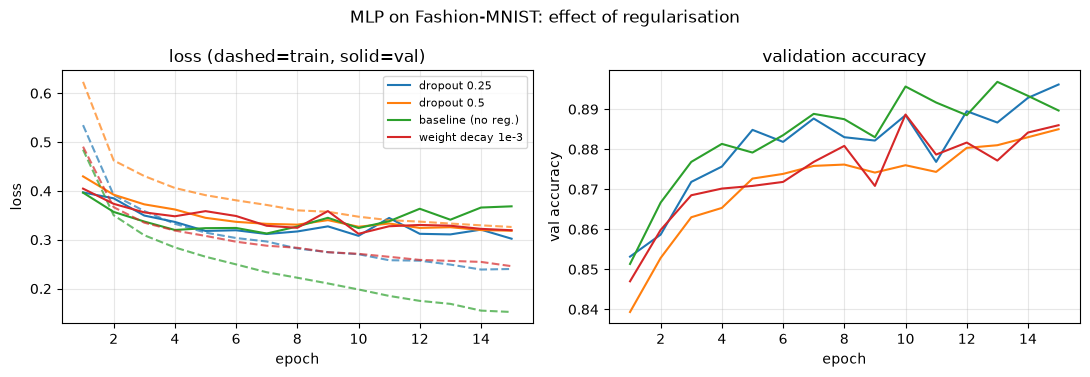

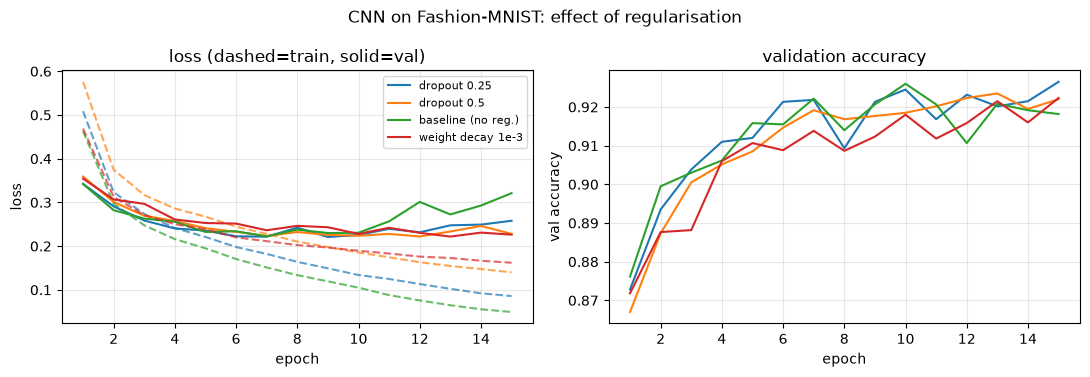

#1 MLP [architecture: depth=3] val_acc=0.9003
    {'model': 'mlp', 'hidden': 256, 'depth': 3, 'act': 'relu', 'init': 'default', 'opt': 'adam', 'lr': 0.001, 'wd': 0.0, 'dropout': 0.0}
#2 CNN [combined: dropout=0.25, channels=(64, 128)] val_acc=0.9272
    {'model': 'cnn', 'channels': (64, 128), 'kernel': 3, 'fc': 128, 'act': 'relu', 'init': 'default', 'opt': 'adam', 'lr': 0.001, 'wd': 0.0, 'dropout': 0.25}
#3 CNN [regularization: dropout=0.25] val_acc=0.9265
    {'model': 'cnn', 'channels': (32, 64), 'kernel': 3, 'fc': 128, 'act': 'relu', 'init': 'default', 'opt': 'adam', 'lr': 0.001, 'wd': 0.0, 'dropout': 0.25}


In [7]:
def find(rows, factor, name): # "Quick utility to dig out a specific experiment result
    return next(r for r in rows if r["factor"] == factor and r["name"] == name)

def plot_curves(results, labels, title, fname): # Draws matplotlib learning curves comparing train vs val loss and val accuracy
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    
    for r, lab in zip(results, labels):
        ep = np.arange(1, len(r["hist"]["val_acc"]) + 1)
        l, = axes[0].plot(ep, r["hist"]["train_loss"], ls="--", alpha=.7)
        axes[0].plot(ep, r["hist"]["val_loss"], color=l.get_color(), label=lab)
        axes[1].plot(ep, r["hist"]["val_acc"], color=l.get_color(), label=lab)   
    axes[0].set(xlabel="epoch", ylabel="loss", title="loss (dashed=train, solid=val)")
    axes[1].set(xlabel="epoch", ylabel="val accuracy", title="validation accuracy")
    for a in axes:
        a.grid(alpha=.3)
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / fname, dpi=200)
    plt.show()

# Generate the regularization plot for both models
for m in ("mlp", "cnn"):
    rows = all_rows[m]
    sel = [find(rows, "regularization", "dropout=0.25"), find(rows, "regularization", "dropout=0.5"),
        find(rows, "init", "baseline"), 
        find(rows, "regularization", "wd=0.001")]
    plot_curves(sel, ["dropout 0.25", "dropout 0.5", "baseline (no reg.)", "weight decay 1e-3"],
                f"{m.upper()} on Fashion-MNIST: effect of regularisation", f"curves_{m}_regularization.png")

def select_top3(rows_by_model): # Finds the #1 MLP, the #1 CNN, and the overall 3rd best model (that is distinct)
    flat = [r for rows in rows_by_model.values() for r in rows]
    best_mlp = max((r for r in flat if r["model"] == "mlp"), key=lambda r: r["val_acc"])
    best_cnn = max((r for r in flat if r["model"] == "cnn"), key=lambda r: r["val_acc"])
    # Filter out the top 2 and any exact duplicates of their configs
    rest = [r for r in flat if r is not best_mlp and r is not best_cnn and repr(sorted(r["cfg"].items())) not in
            {repr(sorted(best_mlp["cfg"].items())), repr(sorted(best_cnn["cfg"].items()))}]  
    third = max(rest, key=lambda r: r["val_acc"])
    return [best_mlp, best_cnn, third]
# Print our podium winners
top3 = select_top3(all_rows)
for i, r in enumerate(top3, 1):
    print(f"#{i} {r['model'].upper()} [{r['factor']}: {r['name']}] val_acc={r['val_acc']:.4f}\n    {r['cfg']}")

CIFAR-10 (3, 32, 32) train/val/test: (45000, 5000, 10000)
cfg1_mlp   Fashion-MNIST  val=0.9003 test=0.8943
cfg1_mlp   CIFAR-10       val=0.5418 test=0.5384
cfg2_cnn   Fashion-MNIST  val=0.9272 test=0.9196
cfg2_cnn   CIFAR-10       val=0.7470 test=0.7348
cfg3_cnn   Fashion-MNIST  val=0.9265 test=0.9250
cfg3_cnn   CIFAR-10       val=0.7422 test=0.7302

Final comparison table:
  config       dataset  val_acc  test_acc  train_acc    gap  n_params
cfg1_mlp Fashion-MNIST   0.9003    0.8943     0.9410 0.0407    335114
cfg1_mlp      CIFAR-10   0.5418    0.5384     0.6961 0.1543    920842
cfg2_cnn Fashion-MNIST   0.9272    0.9196     0.9719 0.0447    878730
cfg2_cnn      CIFAR-10   0.7470    0.7348     0.8888 0.1418   1125642
cfg3_cnn Fashion-MNIST   0.9265    0.9250     0.9671 0.0406    421642
cfg3_cnn      CIFAR-10   0.7422    0.7302     0.8677 0.1255    545098

Test accuracy side by side:
dataset   CIFAR-10  Fashion-MNIST   drop
config                                  
cfg1_mlp    0.5384    

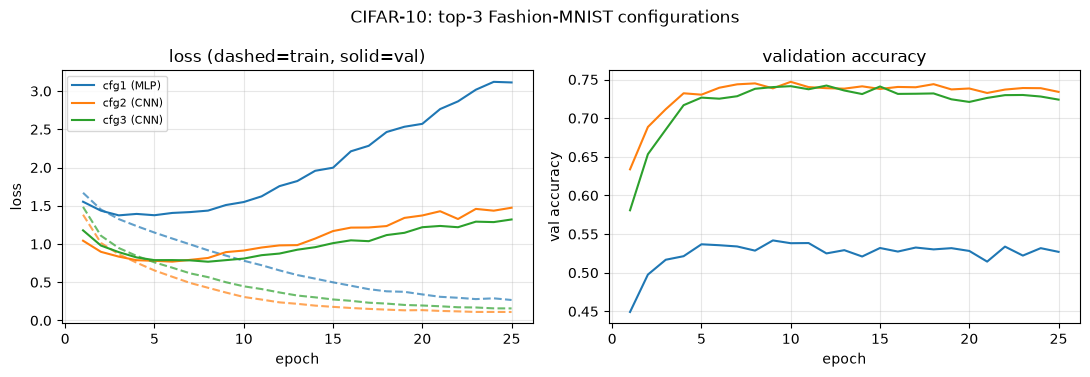

In [8]:
# Load CIFAR-10 data
data_c10 = load_data("cifar10")
print("CIFAR-10", data_c10["in_shape"], "train/val/test:", data_c10["sizes"])
final_rows, final_hist = [], {}
for i, r in enumerate(top3, 1):
    tag = f"cfg{i}_{r['model']}"  
    for ds_name, data, ep in (("Fashion-MNIST", data_fm, EPOCHS_FM), ("CIFAR-10", data_c10, EPOCHS_CIFAR)):
        # Retrain the model. Notice `keep_model=True` so we have a PyTorch object to test
        res = run_experiment(r["cfg"], data, ep, keep_model=True)
        # The moment of truth: Evaluating on the test set!
        _, test_acc = evaluate(res["torch_model"], data["test"])
        final_rows.append({
            "config": tag, "dataset": ds_name, "val_acc": res["val_acc"],
            "test_acc": test_acc, "train_acc": res["train_acc_at_best"],
            "gap": res["gap"], "n_params": res["n_params"]
        })
        final_hist[(tag, ds_name)] = res
        print(f"{tag:<10} {ds_name:<14} val={res['val_acc']:.4f} test={test_acc:.4f}")
# Save the final results
df_final = pd.DataFrame(final_rows)
df_final.to_csv(OUT_DIR / "final_comparison.csv", index=False)
print("\nFinal comparison table:")
print(df_final.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
# Pivot the table to easily see the drop in performance between Fashion-MNIST and CIFAR-10
side = df_final.pivot(index="config", columns="dataset", values="test_acc")
side["drop"] = side["Fashion-MNIST"] - side["CIFAR-10"]
print("\nTest accuracy side by side:")
print(side.to_string(float_format=lambda v: f"{v:.4f}"))
side.to_csv(OUT_DIR / "side_by_side_test_acc.csv")
# Plot the CIFAR-10 learning curves for these top 3 models
res_c10 = [final_hist[(f"cfg{i}_{r['model']}", "CIFAR-10")] for i, r in enumerate(top3, 1)]
plot_curves(res_c10, [f"cfg{i} ({r['model'].upper()})" for i, r in enumerate(top3, 1)],
            "CIFAR-10: top-3 Fashion-MNIST configurations", "curves_cifar10_top3.png")